Best Delivery Route:
[2, 3, 10, 6, 7, 8, 5, 9, 4, 1]

Minimum Delivery Distance:
34.69


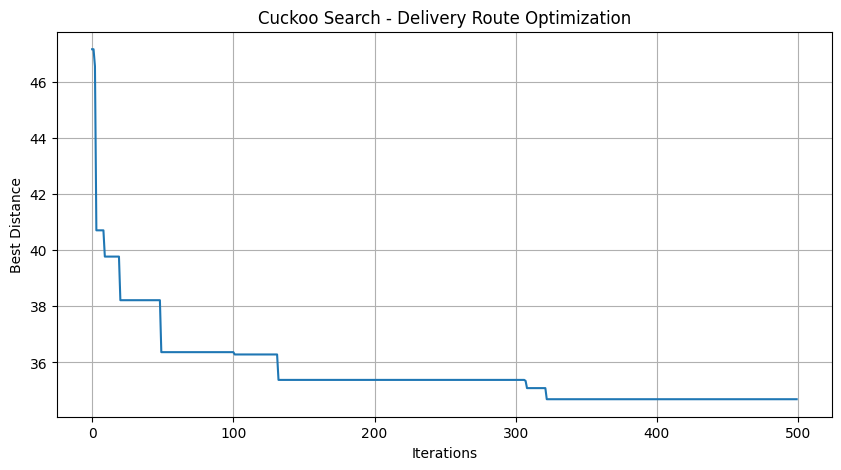

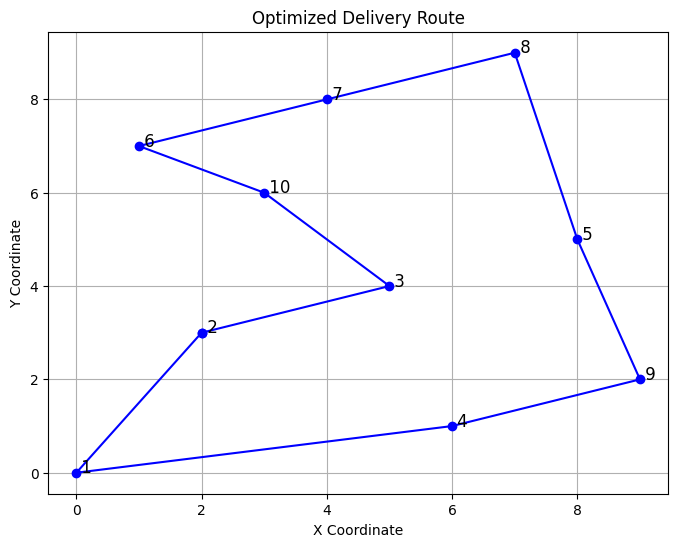

In [2]:

import numpy as np
import matplotlib.pyplot as plt
import random
import math


locations = np.array([
    [0, 0],
    [2, 3],
    [5, 4],
    [6, 1],
    [8, 5],
    [1, 7],
    [4, 8],
    [7, 9],
    [9, 2],
    [3, 6]
])

n = len(locations)


num_nests = 25
pa = 0.25
iterations = 500
alpha = 0.01
beta = 1.5


distance_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        distance_matrix[i][j] = np.linalg.norm(
            locations[i] - locations[j]
        )


def fitness(route):
    total_distance = 0

    for i in range(len(route) - 1):
        total_distance += distance_matrix[
            route[i]
        ][route[i + 1]]

    total_distance += distance_matrix[
        route[-1]
    ][route[0]]

    return total_distance


def levy_flight():
    sigma = (
        math.gamma(1 + beta) * math.sin(np.pi * beta / 2) /
        (
            math.gamma((1 + beta) / 2)
            * beta
            * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / abs(v) ** (1 / beta)


def generate_new_solution(route):
    new_route = route.copy()

    step = int(abs(levy_flight()) * n * alpha) + 1

    i, j = random.sample(range(n), 2)
    new_route[i], new_route[j] = new_route[j], new_route[i]

    for _ in range(step):
        i, j = random.sample(range(n), 2)
        new_route[i], new_route[j] = new_route[j], new_route[i]

    return new_route


nests = [
    list(np.random.permutation(n))
    for _ in range(num_nests)
]

best_route = None
best_distance = float('inf')
history = []


for iteration in range(iterations):

    for i in range(num_nests):
        new_route = generate_new_solution(nests[i])

        if fitness(new_route) < fitness(nests[i]):
            nests[i] = new_route

    scores = [fitness(route) for route in nests]


    for i in range(num_nests):
        if scores[i] < best_distance:
            best_distance = scores[i]
            best_route = nests[i].copy()


    num_abandon = int(pa * num_nests)

    worst_indices = np.argsort(scores)[-num_abandon:]

    for idx in worst_indices:
        nests[idx] = list(np.random.permutation(n))

    history.append(best_distance)


print("Best Delivery Route:")
print([int(x + 1) for x in best_route])

print("\nMinimum Delivery Distance:")
print(round(best_distance, 2))


plt.figure(figsize=(10, 5))
plt.plot(history)
plt.xlabel("Iterations")
plt.ylabel("Best Distance")
plt.title("Cuckoo Search - Delivery Route Optimization")
plt.grid()
plt.show()


plt.figure(figsize=(8, 6))

route_coordinates = locations[best_route]
route_coordinates = np.vstack([
    route_coordinates,
    route_coordinates[0]
])

plt.plot(
    route_coordinates[:, 0],
    route_coordinates[:, 1],
    'b-o'
)

for i, point in enumerate(locations):
    plt.text(
        point[0],
        point[1],
        f' {i + 1}',
        fontsize=12
    )

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.title("Optimized Delivery Route")
plt.grid()
plt.show()
